# Projeto Prático 2.1 - Aprendizado Supervisionado no Neurônio Perceptron

- Redes Neurais Artificiais 2026.2
- Profa. Elloá B. Guedes (ebgcosta@uea.edu.br)
- Escola Superior de Tecnologia - Universidade do Estado do Amazonas
- Enunciado: [rna-2026.2-pp2.1.pdf](rna-2026.2-pp2.1.pdf)

### Equipe

- Bernardo Gontijo Fernandes (http://github.com/bernardo-gontijo)
  - Matrícula: **[2415080002]**
- Mateus Cabral Pinheiro (http://github.com/mateuscpin)
  - Matrícula: **[2415080017]**

### Apresentação

O objetivo deste projeto é implementar o treinamento supervisionado do neurônio Perceptron de Rosenblatt para problemas de classificação, realizar experimentos e avaliar uma solução em um problema não linearmente separável.

### Identificador da Equipe

- Soma dos últimos dígitos das matrículas e calculo do resto da divisão por 4.

**Identificador:** [2 + 7 = 9] -> [9 mod 4 = 1] -> [1]

### Base de Dados e Convenções

Os arquivos têm extensão `.txt`, mas contém dados binários de um `numpy.ndarray`, com dimensões `(m, 1, 3)`. Cada exemplo representa um ponto no plano e seu rótulo: `(x1, x2, yd)`.

- Classe 0: **vermelho**.
- Classe 1: **azul**.
- Parte I: `dados/dataAll20262.txt`.
- Parte II: Como o identificador é [1] `dados/data120262.txt`.
- Parte III: `dados/dataHoldout20262.txt`.

### Bibliotecas

Respeitar a restrição de uso de scikit-learn somente para métricas. O pacote prettytable é recomendado pelo enunciado para a tabela da Parte II.

In [1]:
import pandas as pd
import numpy as np
import random as rd
import math
import matplotlib.pyplot as plt
from prettytable import PrettyTable

## Parte I - Resolvendo um Problema Linearmente Separável

Utilizar o arquivo `dados/dataAll20262.txt` e construir o algoritmo de treinamento do neurônio Perceptron para resolver o problema de classificação proposto.

### Abertura do Dataset

- Carregar o arquivo binário como um array NumPy.
- Visualizar os primeiros exemplos e verificar as dimensões do conjunto.
- Identificar as duas coordenadas de entrada e o rótulo de cada exemplo.

In [2]:
dados_originais = np.load("dados/dataAll20262.txt", allow_pickle=False)
print("Dimensões originais:", dados_originais.shape)

dados = dados_originais.squeeze(axis=1) # Tirar a dimensão intermediaria "1" e separar entradas e rótulos

# Colocar para DataFrame

df = pd.DataFrame(dados, columns=["x1", "x2", "yd"])
df["yd"] = df["yd"].astype(int) # Colocando os rótulos para int

# Nomeando os dados para o treinamento

X = df[["x1", "x2"]].to_numpy(dtype=float)
y = df["yd"].to_numpy(dtype=int)

display(df.head())

print("Quantidade de exemplos por classe:") # Observar a distribuição
print(df["yd"].value_counts().sort_index())


Dimensões originais: (1000, 1, 3)


,x1,x2,yd
0,547.912097,-122.243120,1
1,717.195840,394.736058,0
2,-811.645304,951.244703,0
3,522.279404,572.128611,0
4,-743.772735,-99.228124,0


Quantidade de exemplos por classe:
yd
0    500
1    500
Name: count, dtype: int64


### Visualização Inicial dos Exemplos

- Construir um gráfico de dispersão com todos os exemplos.
- Representar a classe 0 em vermelho e a classe 1 em azul.
- Rotular os eixos e incluir uma legenda que identifique as classes.

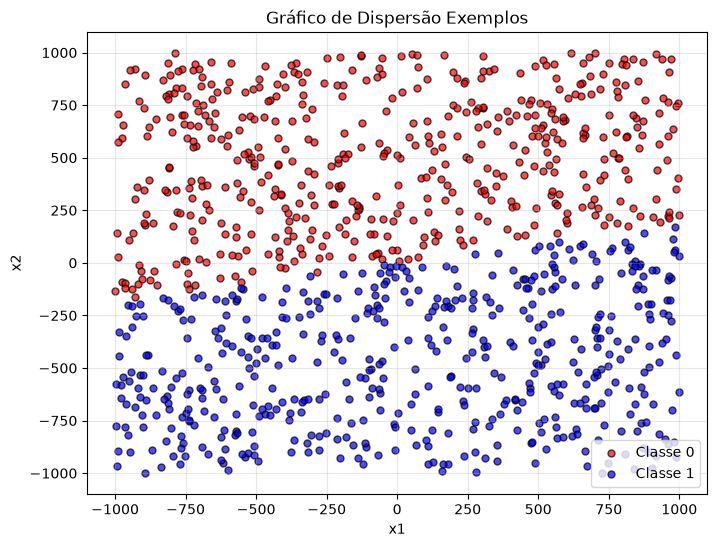

In [3]:
classe_0 = df[df["yd"] == 0]
classe_1 = df[df["yd"] == 1]

plt.figure(figsize=(8, 6))
plt.scatter(classe_0["x1"], classe_0["x2"], color="red", label="Classe 0", s=25, alpha=0.7, edgecolors='black')
plt.scatter(classe_1["x1"], classe_1["x2"], color="blue", label="Classe 1", s=25, alpha=0.7, edgecolors='black')
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Gráfico de Dispersão Exemplos")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Construção do Neurônio Perceptron e Configuração Treinamento

- Implementar o cálculo da entrada do neurônio com operações NumPy.
- Implementar a função de ativação degrau com limiar igual a zero.
- Registrar a convenção adotada para os pesos e o termo de polarização.
- Implementar a regra de ajuste dos pesos e a organização do treinamento em épocas.
- Registrar separadamente a quantidade de ajustes e a quantidade de épocas.
- Definir a taxa de aprendizado em **0,1**.
- Inicializar os pesos aleatoriamente com distribuição uniforme no intervalo **(-0,5; +0,5)**.
- Imprimir o vetor inicial de pesos no início da execução.
- Utilizar a função degrau com limiar igual a zero.

In [4]:
class Perceptron:
    def __init__(
        self,
        eta=0.1,
        intervalo_pesos=(-0.5, 0.5),
        n_epocas=None,
        embaralhar=False,
        semente=None
    ):
        self.eta = eta
        self.intervalo_pesos = intervalo_pesos
        self.n_epocas = n_epocas
        self.embaralhar = embaralhar
        self.semente = semente

    def net_input(self, X):
        """Calcula a soma ponderada das entradas mais o bias."""
        return np.dot(X, self.w_[1:]) + self.w_[0]

    def predict(self, X):
        """Aplica o degrau com limiar zero."""
        return np.where(self.net_input(X) >= 0.0, 1, 0)

    def fit(self, X, y):
        """Inicializa os pesos e realiza o treinamento."""
        rng = np.random.default_rng(self.semente)

        minimo, maximo = self.intervalo_pesos

        # Um peso para cada entrada, mais um para o bias.
        self.w_ = rng.uniform(
            minimo,
            maximo,
            size=1 + X.shape[1]
        )

        self.pesos_iniciais_ = self.w_.copy()
        print("Pesos iniciais [bias, w1, w2]:", self.pesos_iniciais_)

        self.ajustes_ = 0
        self.epocas_ = 0

        while (
            self.n_epocas is None
            or self.epocas_ < self.n_epocas
        ):
            ajustes_epoca = 0

            if self.embaralhar:
                indices = rng.permutation(X.shape[0])
            else:
                indices = np.arange(X.shape[0])

            for i in indices:
                xi = X[i]
                desejado = y[i]

                previsto = self.predict(xi)
                erro = desejado - previsto

                if erro != 0:
                    update = self.eta * erro

                    self.w_[1:] += update * xi
                    self.w_[0] += update

                    self.ajustes_ += 1
                    ajustes_epoca += 1

            self.epocas_ += 1

            if self.epocas_ % 1000 == 0:
                print(
                    f"Época {self.epocas_} | "
                    f"Ajustes nesta época: {ajustes_epoca} | "
                    f"Total de ajustes: {self.ajustes_}",
                    flush=True
                )

            # Sem limite definido, treina até uma época sem erros.
            if self.n_epocas is None and ajustes_epoca == 0:
                break

        return self

### Treinamento até a Convergência

- Executar o treinamento até que não haja erros para todos os exemplos do conjunto de treinamento.
- Registrar o vetor de pesos obtido.
- Imprimir o número total de ajustes no vetor de pesos.
- Imprimir o número de épocas até a convergência.

In [5]:
ppn = Perceptron(
    eta=0.1,
    intervalo_pesos=(-0.5, 0.5),
    n_epocas=None,
    embaralhar=False,
    semente=None
)

ppn.fit(X, y)
previsoes = ppn.predict(X)
quantidade_erros = np.count_nonzero(previsoes != y)

print("Pesos finais [bias, w1, w2]: ", ppn.w_)
print("Erros após o treinamento:", quantidade_erros)
print("Total de ajustes:", ppn.ajustes_)
print("Total de épocas:", ppn.epocas_)

Pesos iniciais [bias, w1, w2]: [-0.35387386  0.29052471  0.06344647]
Pesos finais [bias, w1, w2]:  [  -0.75387386   77.33145777 -386.10599543]
Erros após o treinamento: 0
Total de ajustes: 42
Total de épocas: 3


### Visualização da Solução
- Apresentar um gráfico com todos os exemplos e a reta que separa as classes, obtida pelo treinamento.
- Classe 0: vermelho; Classe 1: azul 

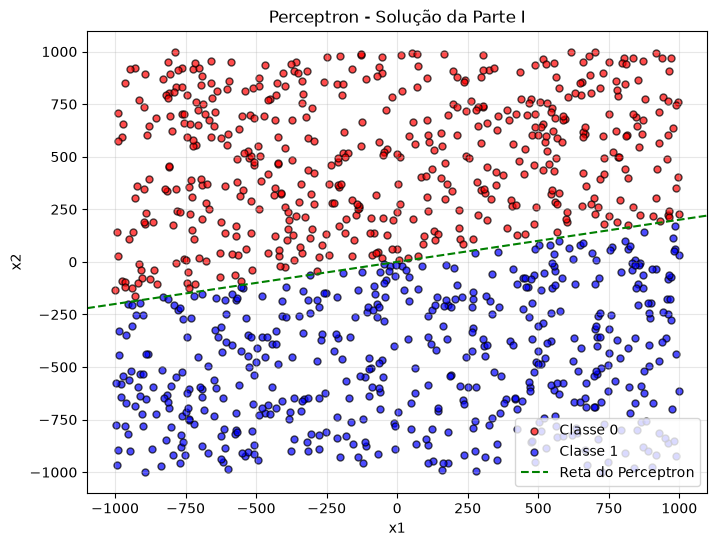

In [6]:
"""Função para desenhar a reta definida pelos pesos aprendidos."""
def plot_decision_boundary(pesos, limites_x):
    bias, w1, w2 = pesos

    if w2 != 0:
        x1 = np.linspace(*limites_x, 100)
        x2 = -(bias + w1 * x1) / w2
        plt.plot(x1, x2, "g--", label="Reta do Perceptron")
        
    elif w1 != 0:
        plt.axvline(-bias / w1, color="green", linestyle="--", label="Reta do Perceptron")

plt.figure(figsize=(8, 6))

plt.scatter(classe_0["x1"], classe_0["x2"], color="red", label="Classe 0", s=25, alpha=0.7, edgecolors='black')
plt.scatter(classe_1["x1"], classe_1["x2"], color="blue", label="Classe 1", s=25, alpha=0.7, edgecolors='black')

"""Guarda os limites definidos pelos exemplos."""
limites_x = plt.xlim()
limites_y = plt.ylim()

plot_decision_boundary(ppn.w_, limites_x)

plt.xlim(limites_x)
plt.ylim(limites_y)
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()
plt.title("Perceptron - Solução da Parte I")
plt.grid(alpha=0.3)
plt.show()

## Parte II - Experimentação

Reutilizar o algoritmo construído na Parte I e utilizar o arquivo correspondente ao identificador da equipe. Comparar seis configurações, executando dez repetições de cada uma.

### Abertura do Dataset: `dados\data120262.txt`

- Carregar os exemplos e conferir as dimensões e os rótulos.


In [7]:
dados1_originais = np.load("dados/data120262.txt", allow_pickle=False)
print("Dimensões originais:", dados1_originais.shape)

dados1 = dados1_originais.squeeze(axis=1) # Tirar a dimensão intermediaria "1" e separar entradas e rótulos

# Colocar para DataFrame

df1 = pd.DataFrame(dados1, columns=["x1", "x2", "yd"])
df1["yd"] = df1["yd"].astype(int) # Colocando os rótulos para int

# Nomeando os dados para o treinamento

X_1 = df1[["x1", "x2"]].to_numpy(dtype=float)
y_1 = df1["yd"].to_numpy(dtype=int)

display(df1.head())

print("Quantidade de exemplos por classe:") # Observar a distribuição
print(df1["yd"].value_counts().sort_index())


Dimensões originais: (1000, 1, 3)


,x1,x2,yd
0,304.598525,-912.449353,0
1,-959.940826,678.425165,0
2,174.286095,-550.589540,0
3,503.584544,-472.615605,1
4,-160.044181,-97.937226,0


Quantidade de exemplos por classe:
yd
0    446
1    554
Name: count, dtype: int64


### Configurações dos Experimentos

Considerar todas as combinações entre as taxas de aprendizado **0,4**, **0,1** e **0,01** e os intervalos de inicialização uniforme **(-100; +100)** e **(-0,5; +0,5)**.

| Configuração | Taxa de aprendizado | Intervalo de pesos |
| --- | --- | --- |
| 1 | 0,4 | (-100; +100) |
| 2 | 0,4 | (-0,5; +0,5) |
| 3 | 0,1 | (-100; +100) |
| 4 | 0,1 | (-0,5; +0,5) |
| 5 | 0,01 | (-100; +100) |
| 6 | 0,01 | (-0,5; +0,5) |

Executar **10 repetições por configuração**, totalizando **60 execuções**.

### Execução e Registro das Repetições

Durante as execuções preliminares com as coordenadas originais, observou-se um custo elevado de treinamento, o que impediu o encerramento do treinamento, que não passava da primeira repetição. Como as coordenadas apresentavam magnitudes próximas de $10^3$, aplicou-se a transformação $X'=X/100$ às duas características, preservando os rótulos e a separabilidade linear. O **reescalonamento** modifica a magnitude das atualizações dos pesos em relação ao bias. A mesma transformação foi aplicada às seis configurações, mantendo as taxas de aprendizado, os intervalos de inicialização e as dez repetições solicitadas. Assim, as estatísticas e conclusões apresentadas referem-se aos dados reescalados.

In [8]:
etas = (0.4, 0.1, 0.01)
intervalos_pesos = ((-100, 100), (-0.5, 0.5))
n_repeticoes = 10

registros = [] # Lista apenas para resultados dos experimentos
configuracao = 0 # Inicialmente em 0

"""Reescalonamento das entradas"""
escala_1 = 100.0
X_1_treino = X_1 / escala_1 

for eta in etas:
    for intervalo in intervalos_pesos:
        configuracao += 1
        
        """Demostracao da configuracao de treino"""
        print(f"\nConfiguracao {configuracao}")
        print(f"Taxa de aprendizado: {eta}")
        print(f"Intervalo de Pesos: {intervalo}")

        for repeticao in range(1, n_repeticoes + 1):
            """Semente para manter reprodutibilidade com função para ser de 1 a 60"""
            semente = (configuracao - 1) * n_repeticoes + repeticao

            print(f"\nRepetição {repeticao}")

            ppn1 = Perceptron(
                eta=eta,
                intervalo_pesos=intervalo,
                n_epocas=None,
                embaralhar=False,
                semente=semente
            )
            
            ppn1.fit(X_1_treino, y_1)

            registros.append({
                "configuracao": configuracao,
                "eta": eta,
                "intervalo_pesos": intervalo,
                "repeticao": repeticao,
                "semente": semente,
                "ajustes": ppn1.ajustes_,
                "epocas": ppn1.epocas_
            })

            print(
                f"Ajustes: {ppn1.ajustes_} |" f"Épocas: {ppn1.epocas_}"
            )


Configuracao 1
Taxa de aprendizado: 0.4
Intervalo de Pesos: (-100, 100)

Repetição 1
Pesos iniciais [bias, w1, w2]: [  2.36432494  90.09273927 -71.16807746]
Ajustes: 1689 |Épocas: 320

Repetição 2
Pesos iniciais [bias, w1, w2]: [-47.67757315 -40.30177132  62.84514812]
Ajustes: 1967 |Épocas: 353

Repetição 3
Pesos iniciais [bias, w1, w2]: [-82.87016657 -52.63789868  60.25489304]
Ajustes: 1786 |Épocas: 313

Repetição 4
Pesos iniciais [bias, w1, w2]: [88.61122111  2.26551056 95.24874114]
Ajustes: 83 |Épocas: 8

Repetição 5
Pesos iniciais [bias, w1, w2]: [61.00058475 61.58815795  3.06511221]
Ajustes: 45 |Épocas: 4

Repetição 6
Pesos iniciais [bias, w1, w2]: [  7.63287029 -31.34582604 -26.18655204]
Ajustes: 1858 |Épocas: 337

Repetição 7
Pesos iniciais [bias, w1, w2]: [25.01909332 79.44276019 55.13713805]
Ajustes: 844 |Épocas: 158

Repetição 8
Pesos iniciais [bias, w1, w2]: [-34.60554468  97.45536867 -36.2578323 ]
Ajustes: 1517 |Épocas: 263

Repetição 9
Pesos iniciais [bias, w1, w2]: [ 74.

In [9]:
"""Criando Dataframe de resultados dos treinamentos"""
resultados = pd.DataFrame(registros)

print(f"\nTotal de execuções registradas: {len(resultados)}")
display(resultados)


Total de execuções registradas: 60


,configuracao,eta,intervalo_pesos,repeticao,semente,ajustes,epocas
0,1,0.40,"(-100, 100)",1,1,1689,320
1,1,0.40,"(-100, 100)",2,2,1967,353
2,1,0.40,"(-100, 100)",3,3,1786,313
3,1,0.40,"(-100, 100)",4,4,83,8
4,1,0.40,"(-100, 100)",5,5,45,4
5,1,0.40,"(-100, 100)",6,6,1858,337
6,1,0.40,"(-100, 100)",7,7,844,158
7,1,0.40,"(-100, 100)",8,8,1517,263
8,1,0.40,"(-100, 100)",9,9,110,5
9,1,0.40,"(-100, 100)",10,10,118,6


### Síntese dos Resultados em Tabela

Para cada configuração, calcular sobre as dez execuções:

- Média e Desvio padrão da quantidade de ajustes efetuados no vetor de pesos.
- Menor número de épocas até a convergência.
- Maior número de épocas até a convergência.

Apresentar uma tabela com as colunas **Taxa de Aprendizado**, **Intervalo de Pesos**, **Quantidade de Ajustes (média ± desvio padrão)**, **Mínimo de épocas** e **Máximo de épocas**.


In [10]:
"""Calcular métricas com Pandas"""
sintese = (
    resultados
    .groupby(["configuracao", "eta", "intervalo_pesos"], sort=True)
    .agg(
        media_ajustes=("ajustes", "mean"),
        desvio_padrao_ajustes=("ajustes", "std"),
        minimo_epocas=("epocas", "min"),
        maximo_epocas=("epocas", "max")
    ).reset_index()
)

"""Criar tabela e atributos"""
tabela = PrettyTable()
tabela.field_names = [
    "Taxa de Aprendizado",
    "Intervalo de Pesos",
    "Quantidade de Ajustes (média ± desvio padrão)",
    "Mínimo de Épocas",
    "Máximo de Épocas"
]

"""Preencher as linhas da tabela"""
for linha in sintese.itertuples(index=False):
    minimo, maximo = linha.intervalo_pesos
    intervalo = f"({minimo}; +{maximo})"
    ajustes = (f"{linha.media_ajustes:.2f} ± {linha.desvio_padrao_ajustes:.2f}")

    tabela.add_row([
        f"η = {linha.eta}",
        intervalo,
        ajustes,
        int(linha.minimo_epocas),
        int(linha.maximo_epocas)
    ])

print(tabela)


+---------------------+--------------------+-----------------------------------------------+------------------+------------------+
| Taxa de Aprendizado | Intervalo de Pesos | Quantidade de Ajustes (média ± desvio padrão) | Mínimo de Épocas | Máximo de Épocas |
+---------------------+--------------------+-----------------------------------------------+------------------+------------------+
|       η = 0.4       |    (-100; +100)    |                1001.70 ± 841.84               |        4         |       353        |
|       η = 0.4       |    (-0.5; +0.5)    |                1009.50 ± 910.42               |        4         |       375        |
|       η = 0.1       |    (-100; +100)    |                1145.00 ± 881.19               |        3         |       346        |
|       η = 0.1       |    (-0.5; +0.5)    |                1223.90 ± 928.18               |        5         |       393        |
|       η = 0.01      |    (-100; +100)    |               3692.70 ± 2668.96       

### Boxplots dos Experimentos

- Gráfico reunindo os boxplots das seis configurações a partir dos registros das repetições.
- Identificar a taxa de aprendizado e o intervalo de inicialização de cada configuração.
- Explicitar a variável apresentada no eixo vertical: quantidade de ajustes e/ou épocas até a convergência.
- Rotular os eixos e manter a comparação legível.

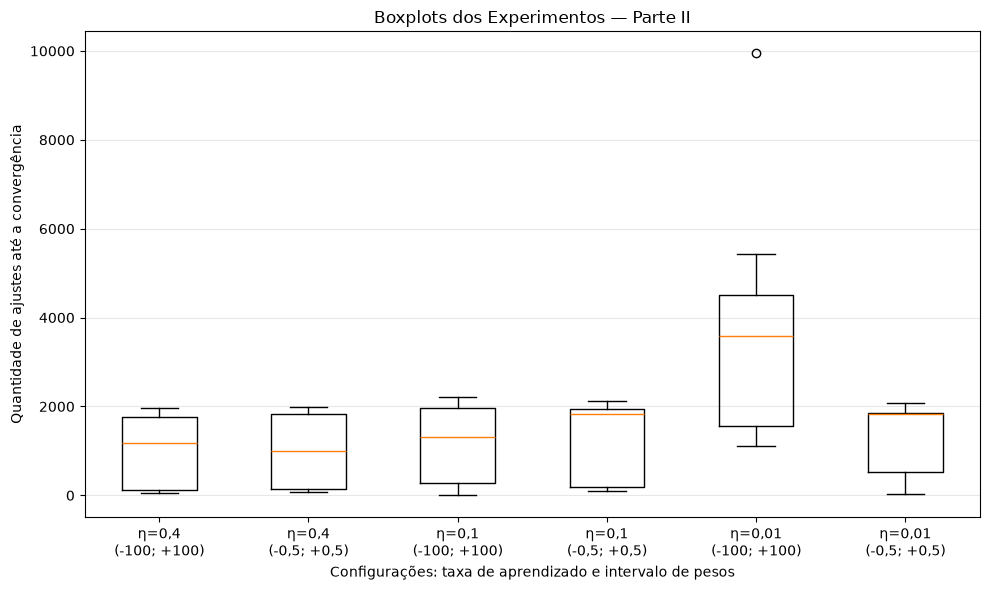

In [11]:
"""Seleção variáveis alvo dos Boxplots"""
grupos_ajustes = [
    resultados.loc[resultados["configuracao"] == i, "ajustes"].to_numpy()
    for i in range(1, 7)
]

grupos_epocas = [
    resultados.loc[resultados["configuracao"] == i, "epocas"].to_numpy()
    for i in range(1, 7)
]

rotulos = [
    "η=0,4\n(-100; +100)",
    "η=0,4\n(-0,5; +0,5)",
    "η=0,1\n(-100; +100)",
    "η=0,1\n(-0,5; +0,5)",
    "η=0,01\n(-100; +100)",
    "η=0,01\n(-0,5; +0,5)"
]

"""Ajustes até a convergência"""
plt.figure(figsize=(10, 6))
plt.boxplot(grupos_ajustes, tick_labels=rotulos)

plt.xlabel("Configurações: taxa de aprendizado e intervalo de pesos")
plt.ylabel("Quantidade de ajustes até a convergência")
plt.title("Boxplots dos Experimentos — Parte II")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

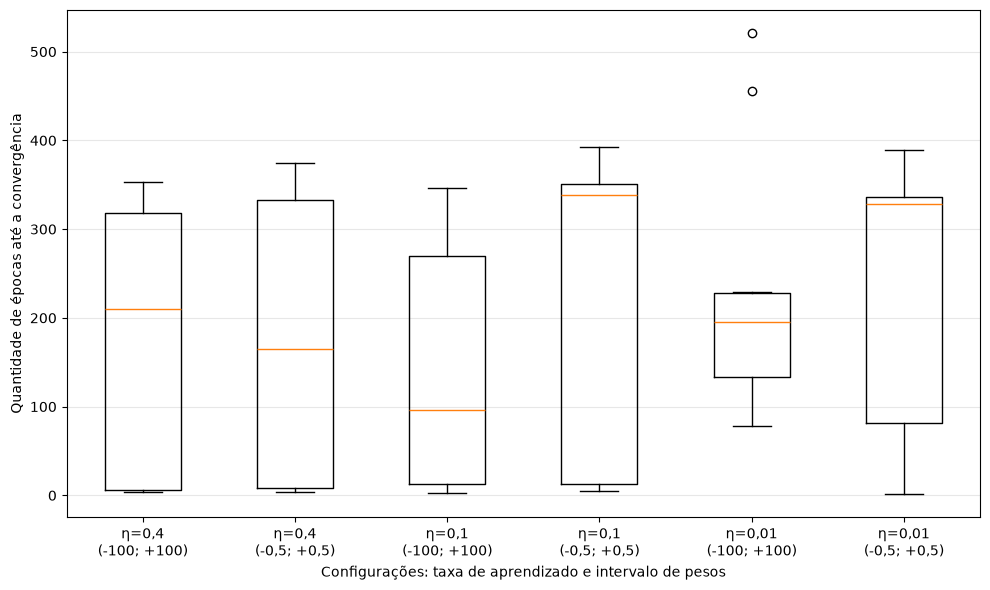

In [12]:
"""Épocas até a convergência"""
plt.figure(figsize=(10, 6))
plt.boxplot(grupos_epocas, tick_labels=rotulos)

plt.xlabel("Configurações: taxa de aprendizado e intervalo de pesos")
plt.ylabel("Quantidade de épocas até a convergência")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Argumentação sobre as Configurações

- **É possivel afirmar acerca da existência de uma configuração melhor ou pior que as demais ou elas são equivalentes?**



Nos experimentos realizados, não houve uma configuração melhor em todos os critérios. As configurações com taxa de aprendizado **0,4** apresentaram as menores médias de ajustes, enquanto **0,1 com pesos em (-100; +100)** apresentou a menor média de épocas. A configuração **0,01 com pesos em (-100; +100)** foi a menos favorável em quantidade de ajustes, sendo a com maior divergência nas métricas.
Portanto, há diferenças observadas no esforço de treinamento, mas não necessariamente é possivel afirmar superioridade geral nem equivalência entre elas, apenas esses destaques de métricas no treinamento.

## Parte III - Validação Holdout em Problema Não Linearmente Separável

### Abertura do Dataset: `dados/dataHoldout20262.txt`

- Carregar os exemplos e conferir as dimensões e os rótulos.

Embora o enunciado descreva o formato `(m, 1, 3)`, o arquivo disponibilizado possui formato `(1000, 3)`. O carregamento abaixo aceita ambos.

Cada exemplo contém duas coordenadas de entrada e um rótulo: `(x1, x2, yd)`.

- Classe 0: vermelho.
- Classe 1: azul.


In [13]:
dados_holdout_originais = np.load(
    "dados/dataHoldout20262.txt",
    allow_pickle=False
)

print("Dimensões originais:", dados_holdout_originais.shape)

if dados_holdout_originais.ndim == 3:
    dados_holdout = dados_holdout_originais.squeeze(axis=1)
else:
    dados_holdout = dados_holdout_originais.copy()

if dados_holdout.ndim != 2 or dados_holdout.shape[1] != 3:
    raise ValueError("Formato esperado: (m, 3) ou (m, 1, 3).")

if not np.isfinite(dados_holdout).all():
    raise ValueError("O conjunto contém valores não finitos.")

if not np.isin(dados_holdout[:, 2], [0, 1]).all():
    raise ValueError("Os rótulos devem ser 0 ou 1.")

df_holdout = pd.DataFrame(
    dados_holdout,
    columns=["x1", "x2", "yd"]
)

df_holdout["yd"] = df_holdout["yd"].astype(int)

X_holdout = df_holdout[["x1", "x2"]].to_numpy(dtype=float)
y_holdout = df_holdout["yd"].to_numpy(dtype=int)

display(df_holdout.head())

print("\nQuantidade de exemplos por classe:")
print(df_holdout["yd"].value_counts().sort_index())

Dimensões originais: (1000, 3)


,x1,x2,yd
0,134.834443,0.901429,1
1,263.517819,0.197317,1
2,56.166711,-0.688011,0
3,20.910100,0.732352,1
4,216.401404,0.416145,1



Quantidade de exemplos por classe:
yd
0    492
1    508
Name: count, dtype: int64


### Visualização Inicial e Separabilidade

- Gráfico inicial com todos os exemplos, evidenciando que o problema não é linearmente separável.

- A distribuição das classes apresenta uma fronteira curvilínea, indicando a limitação de utilizar uma única reta para separá-las perfeitamente. Ainda assim, o Perceptron será treinado para produzir uma aproximação linear.

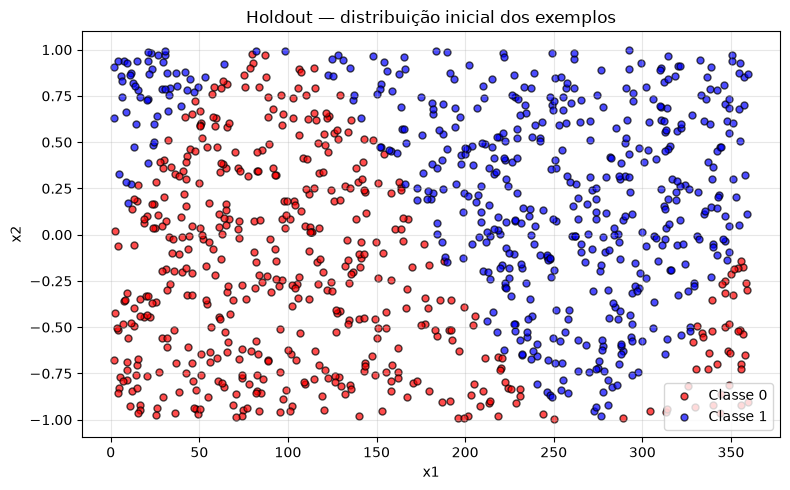

In [42]:
plt.figure(figsize=(8, 5))

for classe, cor in [(0, "red"), (1, "blue")]:
    pontos = X_holdout[y_holdout == classe]

    plt.scatter(
        pontos[:, 0], pontos[:, 1],
        color=cor,
        label=f"Classe {classe}",
        s=25,
        alpha=0.7,
        edgecolors="black"
    )

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Holdout — distribuição inicial dos exemplos")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Preparação dos Dados para Validação Holdout

- Dividir aleatoriamente os exemplos em **70% para treinamento** e **30% para teste**.
- **Random Seed:** 1.
- Registrar a quantidade de exemplos em cada partição.
- Reservar o conjunto de teste para a avaliação.

Como as coordenadas possuem escalas diferentes, será feita a padronização abaixo:

$$
z_j = \frac{x_j - \mu_j}{\sigma_j}
$$

As médias e os desvios padrão serão calculados somente no treinamento e o conjunto de teste utilizará os mesmos valores, sem influenciar na estimativa. A padronização coloca as entradas em escalas comparáveis e preserva a linearidade da fronteira de decisão.

In [24]:
SEMENTE_EQUIPE = 1

rng_holdout = np.random.default_rng(SEMENTE_EQUIPE)
indices_holdout = rng_holdout.permutation(X_holdout.shape[0])

corte = int(0.70 * indices_holdout.size)

idx_treino = indices_holdout[:corte]
idx_teste = indices_holdout[corte:]

X_treino = X_holdout[idx_treino]
y_treino = y_holdout[idx_treino]

X_teste = X_holdout[idx_teste]
y_teste = y_holdout[idx_teste]

print(f"Treinamento: {len(y_treino)} exemplos")
print(f"Teste: {len(y_teste)} exemplos")

distribuicao = pd.DataFrame(
    {
        "Treinamento": np.bincount(y_treino, minlength=2),
        "Teste": np.bincount(y_teste, minlength=2)
    },
    index=pd.Index([0, 1], name="Classe")
)

display(distribuicao)

# Calcula as estatísticas somente sobre o treinamento.
media_treino = X_treino.mean(axis=0)
escala_treino = X_treino.std(axis=0)

# Evita divisão por zero caso alguma coordenada seja constante.
escala_treino = np.where(
    escala_treino == 0,
    1.0,
    escala_treino
)

X_treino_pad = (X_treino - media_treino) / escala_treino
X_teste_pad = (X_teste - media_treino) / escala_treino

print("Médias do treinamento:", media_treino)
print("Escalas utilizadas:", escala_treino)

Treinamento: 700 exemplos
Teste: 300 exemplos


,Treinamento,Teste
Classe,,
0,334,158
1,366,142


Médias do treinamento: [1.76954270e+02 3.03395516e-02]
Escalas utilizadas: [107.80040481   0.56834712]


### Configuração do Perceptron e Fundamentação

**Taxa de aprendizado escolhida:** η = 0,25.

Marsland (2014, seção 3.3.1, p. 46) apresenta o intervalo típico 0,1 < η < 0,4. Adotamos 0,25, também utilizado no exemplo da seção 3.3.4, p. 49. Essa escolha tem fundamentação bibliográfica e não representa uma garantia de desempenho ótimo.

A inicialização com valores aleatórios pequenos, positivos e negativos, é apresentada na seção 3.3.3, p. 47. Neste trabalho, utilizaremos especificamente U(-0,5; +0,5), conforme determinado pelo enunciado.

Configuração adotada:

- Função de ativação degrau com limiar zero.
- Taxa de aprendizado constante de 0,25.
- Pesos iniciais, incluindo o bias, em U(-0,5; +0,5).
- Exatamente 100 épocas.
- Nova ordem aleatória dos exemplos a cada época.
- Semente 1 para tornar a execução reproduzível.

Reutilizaremos a classe `Perceptron` implementada na Parte I, cuja convenção é:

$$
u = b + w_1z_1 + w_2z_2
$$

A saída será 1 quando u ≥ 0 e 0 caso contrário.

In [ ]:
modelo_holdout = Perceptron(
    eta=0.25,
    intervalo_pesos=(-0.5, 0.5),
    n_epocas=100,
    embaralhar=True,
    semente=SEMENTE_EQUIPE
)

print("Taxa de aprendizado:", modelo_holdout.eta)
print("Intervalo inicial:", modelo_holdout.intervalo_pesos)
print("Épocas:", modelo_holdout.n_epocas)
print("Embaralhamento por época:", modelo_holdout.embaralhar)

Taxa de aprendizado: 0.25
Intervalo inicial: (-0.5, 0.5)
Épocas: 100
Embaralhamento por época: True


### Treinamento por 100 Épocas

O treinamento utilizará somente os exemplos da partição de treinamento, com entradas padronizadas.

A cada época, a implementação gera uma nova permutação dos índices e apresenta todos os exemplos uma vez nessa ordem.

Como o problema não é linearmente separável, não exigiremos uma época sem erros. O encerramento ocorrerá após 100 épocas e serão utilizados os pesos finais, sem selecionar pesos pelo desempenho no teste.

Os pesos impressos nesta etapa correspondem às coordenadas padronizadas. Posteriormente, serão convertidos para desenhar a reta nas coordenadas originais.

In [26]:
modelo_holdout.fit(X_treino_pad, y_treino)

print("\nPesos finais [bias, w1, w2]:")
print(modelo_holdout.w_)

print("Total de ajustes:", modelo_holdout.ajustes_)
print("Total de épocas:", modelo_holdout.epocas_)

y_prev_treino = modelo_holdout.predict(X_treino_pad)

print(
    "Erros de classificação no treinamento:",
    np.count_nonzero(y_prev_treino != y_treino)
)

Pesos iniciais [bias, w1, w2]: [ 0.01182162  0.4504637  -0.35584039]

Pesos finais [bias, w1, w2]:
[-0.23817838  0.30702501  0.45947597]
Total de ajustes: 14549
Total de épocas: 100
Erros de classificação no treinamento: 174


### Obtendo Previsões no Conjunto de Teste

Com o treinamento concluído, aplicaremos os pesos finais às entradas de teste padronizadas.

Nesta etapa, nenhuma atualização de pesos será realizada. Cada previsão será comparada ao respectivo rótulo desejado.

A tabela manterá o índice original do exemplo, suas coordenadas, o rótulo real, a previsão e a indicação de acerto.

In [27]:
y_prev_teste = modelo_holdout.predict(X_teste_pad)

comparacao_teste = pd.DataFrame(
    {
        "indice_original": idx_teste,
        "x1": X_teste[:, 0],
        "x2": X_teste[:, 1],
        "real": y_teste,
        "previsto": y_prev_teste,
        "acertou": y_teste == y_prev_teste
    }
)

display(comparacao_teste.head(15))

print(
    "Acertos:",
    np.count_nonzero(y_prev_teste == y_teste)
)

print(
    "Erros:",
    np.count_nonzero(y_prev_teste != y_teste)
)

,indice_original,x1,x2,real,previsto,acertou
0,994,157.266253,0.459016,1,1,True
1,590,346.677121,-0.316256,0,0,True
2,874,273.704336,-0.725781,1,0,False
3,321,76.121283,-0.345005,0,0,True
4,184,70.484809,-0.861277,0,0,True
5,217,30.278450,0.401938,0,0,True
6,587,228.242053,0.079971,1,0,False
7,592,36.903502,0.874457,1,1,True
8,333,88.544782,-0.678637,0,0,True
9,811,202.426854,0.915251,1,1,True


Acertos: 218
Erros: 82


### Matriz de Confusão do Conjunto de Teste

A matriz de confusão apresenta a quantidade de exemplos para cada combinação de classe real e classe prevista.

As linhas representam as classes reais e as colunas representam as previsões.

Considerando a classe 1 como positiva:

| Classe | Previsto 0 | Previsto 1 |
|---|---|---|
| Real 0 | Verdadeiro negativo (TN) | Falso positivo (FP) |
| Real 1 | Falso negativo (FN) | Verdadeiro positivo (TP) |

A diagonal principal contém os acertos. Os elementos fora da diagonal correspondem aos erros.

,Previsto 0,Previsto 1
Real 0,140,18
Real 1,64,78


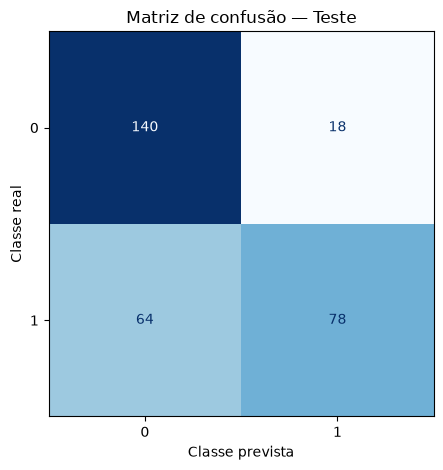

In [28]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

matriz_teste = confusion_matrix(
    y_teste,
    y_prev_teste,
    labels=[0, 1]
)

display(
    pd.DataFrame(
        matriz_teste,
        index=["Real 0", "Real 1"],
        columns=["Previsto 0", "Previsto 1"]
    )
)

ConfusionMatrixDisplay(
    confusion_matrix=matriz_teste,
    display_labels=[0, 1]
).plot(
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.title("Matriz de confusão — Teste")
plt.tight_layout()
plt.show()

### Acurácia, Precisão, Revocação e F-Score

Há uma ambiguidade no enunciado: esta etapa começa solicitando previsões de teste, mas a questão 2 menciona os dados de treinamento e a questão 3 remete é anterior. Organizar os resultados de forma a identificar explicitamente o conjunto avaliado.

- Calcular a **acurácia**, a **precisão**, a **revocação** e o **F-Score** no conjunto de teste, para sustentar a discussão solicitada sobre esse conjunto.
- Apresentar também as mesmas métricas no conjunto de treinamento, contemplando a redação das questões 2 e 3.
- Informar a classe positiva ou a estratégia de agregação utilizada nas métricas.
- Utilizar sklearn.metrics apenas para esses cálculos.
- Dispor os resultados de treino e teste com identificação clara, sem misturá-los.

### Qualidade da Solução perante o Conjunto de Testes

In [32]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

def calcular_metricas(real, previsto):
    return {
        "Acuracia": accuracy_score(real, previsto),

        "Precisao": precision_score(
            real,
            previsto,
            pos_label=1,
            zero_division=0
        ),

        "Recall": recall_score(
            real,
            previsto,
            pos_label=1,
            zero_division=0
        ),

        "F1-score": f1_score(
            real,
            previsto,
            pos_label=1,
            zero_division=0
        )
    }

metricas_holdout = pd.DataFrame(
    {
        "Treinamento": calcular_metricas(
            y_treino,
            y_prev_treino
        ),

        "Teste": calcular_metricas(
            y_teste,
            y_prev_teste
        )
    }
).T

print("Classe positiva: 1.")
display(metricas_holdout.style.format("{:.2%}"))

Classe positiva: 1.


,Acuracia,Precisao,Recall,F1-score
Treinamento,75.14%,87.21%,61.48%,72.12%
Teste,72.67%,81.25%,54.93%,65.55%


### Qualidade da Solução perante o Conjunto de Testes

A análise considera as métricas em conjunto, especialmente os falsos positivos e falsos negativos da classe 1.

Também comparamos treinamento e teste, reconhecendo que os resultados correspondem a uma única divisão holdout e a uma configuração específica de treinamento.

### E sobre a qualidade desta solução?

No conjunto de teste, a solução apresentou acurácia de 72,67%, precisão de 81,25%, recall de 54,93% e F1-score de 65,55%, indicando uma qualidade moderada. A precisão mostra que o neurônio costuma acertar quando prevê a classe 1. Porém, o recall mais baixo revela que ele deixa de reconhecer uma parte significativa dos exemplos dessa classe: foram 64 falsos negativos, contra 18 falsos positivos.

Essa dificuldade é compatível com a natureza do problema. Como as classes não são linearmente separáveis, uma única reta não consegue representar perfeitamente a divisão entre elas. Assim, o modelo encontra uma aproximação, mas ainda apresenta limitações, principalmente na identificação da classe 1.

O desempenho no treinamento foi um pouco superior ao de teste, mas essa proximidade não é suficiente para garantir boa generalização. Além disso, completar 100 épocas não significa que o modelo encontrou a melhor reta possível, e os resultados podem variar em outras divisões dos dados.

### Visualização da Solução: Treinamento e Teste

Apresentaremos a mesma reta de decisão nos dois gráficos:

1. Exemplos de treinamento.
2. Exemplos de teste.

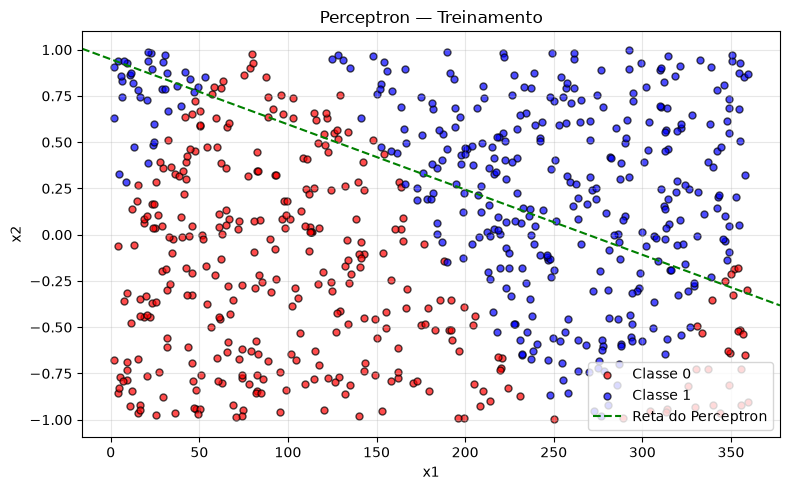

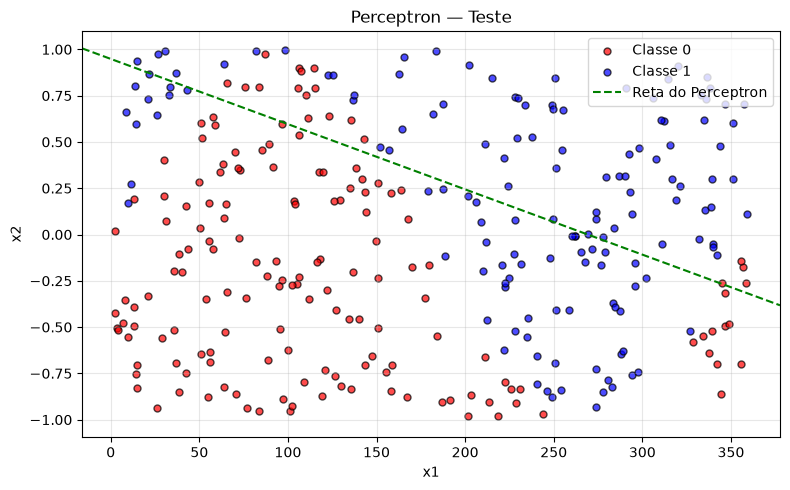

Pesos nas coordenadas originais [bias, w1, w2]:
[-0.76668744  0.00284809  0.80844251]


In [41]:
# Converte os pesos para as coordenadas originais.
pesos_originais = modelo_holdout.w_.copy()
pesos_originais[1:] /= escala_treino
pesos_originais[0] -= np.dot(pesos_originais[1:], media_treino)

# Define limites comuns, com margem de 5%.
margem = 0.05 * np.ptp(X_holdout, axis=0)
minimos = X_holdout.min(axis=0) - margem
maximos = X_holdout.max(axis=0) + margem

limites_x = (minimos[0], maximos[0])
limites_y = (minimos[1], maximos[1])


def mostrar_solucao(entradas, rotulos, titulo):
    plt.figure(figsize=(8, 5))

    for classe, cor in [(0, "red"), (1, "blue")]:
        pontos = entradas[rotulos == classe]

        plt.scatter(
            pontos[:, 0], pontos[:, 1],
            color=cor,
            label=f"Classe {classe}",
            s=25,
            alpha=0.7,
            edgecolors="black"
        )

    plot_decision_boundary(pesos_originais, limites_x)

    plt.xlim(limites_x)
    plt.ylim(limites_y)
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(titulo)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


mostrar_solucao(X_treino, y_treino, "Perceptron — Treinamento")
mostrar_solucao(X_teste, y_teste, "Perceptron — Teste")

print("Pesos nas coordenadas originais [bias, w1, w2]:")
print(pesos_originais)

### Exportação em CSV

In [ ]:
comparacao_teste.to_csv(
    "previsoes_holdout.csv",
    index=False,
    sep=";",
    decimal=",",
    encoding="utf-8-sig"
)

metricas_holdout.to_csv(
    "metricas_holdout.csv",
    index_label="conjunto",
    sep=";",
    decimal=",",
    encoding="utf-8-sig"
)

print("Arquivos salvos:")
print("- previsoes_holdout.csv")
print("- metricas_holdout.csv")

## Referências

### Enunciado

- GUEDES, Elloá B. *Redes Neurais Artificiais — Projeto Prático 2.1: Aprendizado Supervisionado no Neurônio Perceptron*. 2026. [Enunciado disponibilizado](rna-2026.2-pp2.1.pdf).

### Literatura

- MARSLAND, Stephen. *Machine Learning: An Algorithmic Perspective*. 2. ed. Chapman & Hall/CRC, 2014. Seções 2.2.3–2.2.4, 3.3.1, 3.3.3–3.3.4 e 3.4.5.

- HAYKIN, Simon. *Neural Networks and Learning Machines*. 3. ed. Pearson Prentice Hall, 2009. Capítulo 1, seção 1.3, tabela 1.1.

- MANNING, Christopher D.; RAGHAVAN, Prabhakar; SCHÜTZE, Hinrich. *Introduction to Information Retrieval*. Cambridge University Press, 2008. Capítulo 8, seção 8.3. [Capítulo disponibilizado pelos autores](https://nlp.stanford.edu/IR-book/pdf/08eval.pdf).

### Documentação e materiais de apoio

- [NumPy](https://numpy.org/).
- [Documentação do NumPy](https://numpy.org/doc/stable/).
- [Matplotlib — scatter](https://matplotlib.org/3.3.0/api/_as_gen/matplotlib.pyplot.scatter.html).
- [Python Data Science Handbook — Simple Scatter Plots](https://jakevdp.github.io/PythonDataScienceHandbook/04.02-simple-scatter-plots.html).
- [Perceptron with Python — a tutorial](https://urapython.github.io/-perceptron-with-python-a-tutorial/).
- [Cornell — The Perceptron](https://www.cs.cornell.edu/courses/cs4780/2018fa/lectures/lecturenote03.html).
- [Cornell Virtual Workshop — Perceptron](https://cvw.cac.cornell.edu/SciML/mlp/perceptron).
- [PrettyTable](https://pypi.org/project/prettytable/).